In [2]:
from reactit.reactit import ReactionGenerator

In [3]:
rg = ReactionGenerator(["H2","O2","HO2"])

In [4]:
rg.iterate(3)

  0%|          | 0/1 [00:00<?, ?it/s]

['1 H2 + 2 O2 = 2 HO2']

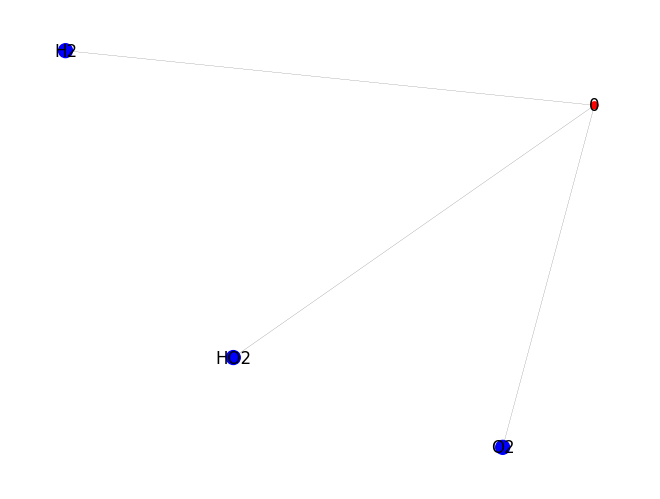

In [5]:
G = rg.to_networkx_graph()

import networkx as nx 

node_colours= []
node_sizes = []
for node in list(G.nodes):
    if isinstance(node,int):
        node_colours.append('red')
        node_sizes.append(25)
    else:
        node_colours.append('blue')
        node_sizes.append(100)

nx.draw_random(G,node_color=node_colours,node_size=node_sizes,width=0.1,with_labels=True,)


In [6]:
import re
from itertools import combinations_with_replacement
from collections import Counter

class RigorousReactionNetworkBuilder:
    def __init__(self, reactants, products, intermediates):
        self.reactants = Counter(reactants)
        self.products = Counter(products)
        self.intermediates = set(intermediates)
        self.all_species = list(set(reactants) | set(products) | self.intermediates)
        
        # Pre-compute the elemental composition of every species
        self.species_composition = {sp: self._parse_formula(sp) for sp in self.all_species}
        
    def _parse_formula(self, formula):
        """Parses a chemical formula string into an elemental count. E.g., 'N2O2' -> {'N': 2, 'O': 2}"""
        matches = re.findall(r'([A-Z][a-z]?)([0-9]*)', formula)
        element_map = Counter()
        for element, count in matches:
            element_map[element] += int(count) if count else 1
        return element_map

    def _is_step_chemically_balanced(self, r_counter, p_counter):
        """Verifies if a specific elementary step obeys conservation of mass."""
        r_atoms = Counter()
        p_atoms = Counter()
        
        for sp, count in r_counter.items():
            for elem, elem_count in self.species_composition[sp].items():
                r_atoms[elem] += elem_count * count
                
        for sp, count in p_counter.items():
            for elem, elem_count in self.species_composition[sp].items():
                p_atoms[elem] += elem_count * count
                
        return r_atoms == p_atoms

    def generate_valid_elementary_steps(self):
        """Generates ONLY chemically balanced unimolecular and bimolecular steps."""
        valid_steps = []
        
        # 1. Unimolecular (A -> B, A -> B + C)
        for r1 in self.all_species:
            for p1 in self.all_species:
                if r1 != p1:
                    r, p = Counter([r1]), Counter([p1])
                    if self._is_step_chemically_balanced(r, p):
                        valid_steps.append((r, p))
            for p1, p2 in combinations_with_replacement(self.all_species, 2):
                if Counter([r1]) != Counter([p1, p2]):
                    r, p = Counter([r1]), Counter([p1, p2])
                    if self._is_step_chemically_balanced(r, p):
                        valid_steps.append((r, p))
                        
        # 2. Bimolecular (A + B -> C, A + B -> C + D)
        for r1, r2 in combinations_with_replacement(self.all_species, 2):
            for p1 in self.all_species:
                r, p = Counter([r1, r2]), Counter([p1])
                if self._is_step_chemically_balanced(r, p):
                    valid_steps.append((r, p))
            for p1, p2 in combinations_with_replacement(self.all_species, 2):
                if Counter([r1, r2]) != Counter([p1, p2]):
                    r, p = Counter([r1, r2]), Counter([p1, p2])
                    if self._is_step_chemically_balanced(r, p):
                        valid_steps.append((r, p))
                        
        return valid_steps

    def _format_step(self, r_counter, p_counter):
        r_str = " + ".join([f"{v} {k}" if v > 1 else k for k, v in r_counter.items()])
        p_str = " + ".join([f"{v} {k}" if v > 1 else k for k, v in p_counter.items()])
        return f"{r_str} -> {p_str}"

    def find_mechanisms(self, max_steps=3):
        allowed_steps = self.generate_valid_elementary_steps()
        valid_mechanisms = []
        
        print(f"Generated {len(allowed_steps)} chemically balanced elementary steps. Searching pathways...")
        
        for n in range(1, max_steps + 1):
            for step_combo in combinations_with_replacement(allowed_steps, n):
                
                # 1. Total net mass balance check
                total_reactants = Counter()
                total_products = Counter()
                for r, p in step_combo:
                    total_reactants.update(r)
                    total_products.update(p)
                    
                net_reactants = total_reactants - total_products
                net_products = total_products - total_reactants
                
                if net_reactants == self.reactants and net_products == self.products:
                    # Check if intermediates leak into final products
                    net_species = set(net_reactants.keys()) | set(net_products.keys())
                    if net_species & self.intermediates:
                        continue
                        
                    # --- FIXED: CAUSALITY & SEQUENCE VALIDATION ---
                    from itertools import permutations
                    
                    seen_sequences = set()
                    
                    for ordered_steps in permutations(step_combo):
                        # Create a unique string representation of the sequence to avoid duplicates safely
                        seq_key = tuple(self._format_step(r, p) for r, p in ordered_steps)
                        if seq_key in seen_sequences:
                            continue
                        seen_sequences.add(seq_key)
                        
                        # Start our inventory with ONLY the global reactants
                        inventory = Counter(self.reactants)
                        valid_sequence = True
                        
                        for r, p in ordered_steps:
                            # Check if we have enough reactants in our current inventory
                            for species, required_amount in r.items():
                                if inventory[species] < required_amount:
                                    valid_sequence = False
                                    break
                            
                            if not valid_sequence:
                                break
                                
                            # Execute the step
                            inventory -= r
                            inventory += p
                            
                        if valid_sequence:
                            valid_mechanisms.append(ordered_steps)
                            
        return valid_mechanisms
         


1. reaction 1 

In [7]:

global_reactants = ['N2', 'O2',"O2"]
global_products = ['NO2', 'NO2']
possible_intermediates = ['N2O','NO','NO3']#,"O4"]
    
builder = RigorousReactionNetworkBuilder(global_reactants, global_products, possible_intermediates)
mechanisms = builder.find_mechanisms(max_steps=4)
    
print(f"\nFound {len(mechanisms)} strictly valid pathways:")
for idx, mech in enumerate(mechanisms, 1):
    print(f"\nPathway {idx}:")
    for r, p in mech:
        print(f"  {builder._format_step(r, p)}")

Generated 12 chemically balanced elementary steps. Searching pathways...

Found 1 strictly valid pathways:

Pathway 1:
  N2 + O2 -> 2 NO
  NO + O2 -> NO3
  NO3 + NO -> 2 NO2


2. Reaction 2 

In [8]:
global_reactants = ['CO2', 'H2']
global_products = ['H2O', 'CO']
possible_intermediates = ['CHO2','CHO','CH2O2',"C2O2","H2O2"]#,
    
builder = RigorousReactionNetworkBuilder(global_reactants, global_products, possible_intermediates)
mechanisms = builder.find_mechanisms(max_steps=4)
    
print(f"\nFound {len(mechanisms)} strictly valid pathways:")
for idx, mech in enumerate(mechanisms, 1):
    print(f"\nPathway {idx}:")
    for r, p in mech:
        print(f"  {builder._format_step(r, p)}")

Generated 32 chemically balanced elementary steps. Searching pathways...

Found 10 strictly valid pathways:

Pathway 1:
  H2 + CO2 -> H2O + CO

Pathway 2:
  H2 + CO2 -> CH2O2
  CH2O2 -> H2O + CO

Pathway 3:
  H2 + CO2 -> CH2O2
  CH2O2 -> H2 + CO2
  H2 + CO2 -> H2O + CO

Pathway 4:
  H2 + CO2 -> H2O + CO
  H2O + CO -> CH2O2
  CH2O2 -> H2O + CO

Pathway 5:
  H2 + CO2 -> H2O + CO
  H2O + CO -> H2 + CO2
  H2 + CO2 -> H2O + CO

Pathway 6:
  H2 + CO2 -> CH2O2
  CH2O2 -> H2 + CO2
  H2 + CO2 -> CH2O2
  CH2O2 -> H2O + CO

Pathway 7:
  H2 + CO2 -> H2O + CO
  H2O + CO -> CH2O2
  CH2O2 -> H2 + CO2
  H2 + CO2 -> H2O + CO

Pathway 8:
  H2 + CO2 -> CH2O2
  CH2O2 -> H2O + CO
  H2O + CO -> CH2O2
  CH2O2 -> H2O + CO

Pathway 9:
  H2 + CO2 -> CH2O2
  CH2O2 -> H2O + CO
  H2O + CO -> H2 + CO2
  H2 + CO2 -> H2O + CO

Pathway 10:
  H2 + CO2 -> H2O + CO
  H2O + CO -> H2 + CO2
  H2 + CO2 -> CH2O2
  CH2O2 -> H2O + CO


3. Reaction 3 `2H2 + O2 = 2H2O` 

In [9]:
global_reactants = ['H2', 'H2',"O2"]
global_products = ['H2O', 'H2O']
possible_intermediates = ["HO2","H2O2","OH","H"]#,
    
builder = RigorousReactionNetworkBuilder(global_reactants, global_products, possible_intermediates)
mechanisms = builder.find_mechanisms(max_steps=5)
    
print(f"\nFound {len(mechanisms)} strictly valid pathways:")
for idx, mech in enumerate(mechanisms, 1):
    print(f"\nPathway {idx}:")
    for r, p in mech:
        print(f"  {builder._format_step(r, p)}")

Generated 34 chemically balanced elementary steps. Searching pathways...

Found 137 strictly valid pathways:

Pathway 1:
  H2 + O2 -> H2O2
  H2O2 + H2 -> 2 H2O

Pathway 2:
  H2 + O2 -> HO2 + H
  HO2 + H -> H2O2
  H2O2 + H2 -> 2 H2O

Pathway 3:
  H2 + O2 -> HO2 + H
  HO2 + H2 -> OH + H2O
  OH + H -> H2O

Pathway 4:
  H2 + O2 -> 2 OH
  2 OH -> H2O2
  H2O2 + H2 -> 2 H2O

Pathway 5:
  H2 + O2 -> 2 OH
  OH + H2 -> H + H2O
  OH + H -> H2O

Pathway 6:
  H2 + O2 -> H2O2
  H2O2 -> HO2 + H
  HO2 + H -> H2O2
  H2O2 + H2 -> 2 H2O

Pathway 7:
  H2 + O2 -> H2O2
  H2O2 -> HO2 + H
  HO2 + H2 -> OH + H2O
  OH + H -> H2O

Pathway 8:
  H2 + O2 -> H2O2
  H2O2 -> 2 OH
  2 OH -> H2O2
  H2O2 + H2 -> 2 H2O

Pathway 9:
  H2 + O2 -> H2O2
  H2O2 -> 2 OH
  OH + H2 -> H + H2O
  OH + H -> H2O

Pathway 10:
  H2 + O2 -> H2O2
  H2O2 -> H2 + O2
  H2 + O2 -> H2O2
  H2O2 + H2 -> 2 H2O

Pathway 11:
  H2 -> 2 H
  H + O2 -> HO2
  HO2 + H -> H2O2
  H2O2 + H2 -> 2 H2O

Pathway 12:
  H2 -> 2 H
  H + O2 -> HO2
  HO2 + H2 -> OH 

3. Reaction 3 `2NO + O2 = 2NO2` 

In [19]:
global_reactants = ['NO', 'NO',"O2"]
global_products = ['NO2', 'NO2']
possible_intermediates = ["NO3","N2O2"]#,
    
builder = RigorousReactionNetworkBuilder(global_reactants, global_products, possible_intermediates)
mechanisms = builder.find_mechanisms(max_steps=5)
    
print(f"\nFound {len(mechanisms)} strictly valid pathways:")
for idx, mech in enumerate(mechanisms, 1):
    print(f"\nPathway {idx}:")
    for r, p in mech:
        print(f"  {builder._format_step(r, p)}")

Generated 10 chemically balanced elementary steps. Searching pathways...

Found 32 strictly valid pathways:

Pathway 1:
  NO + O2 -> NO3
  NO3 + NO -> 2 NO2

Pathway 2:
  2 NO -> N2O2
  N2O2 + O2 -> 2 NO2

Pathway 3:
  NO + O2 -> NO3
  NO3 + NO -> N2O2 + O2
  N2O2 + O2 -> 2 NO2

Pathway 4:
  2 NO -> N2O2
  N2O2 + O2 -> NO3 + NO
  NO3 + NO -> 2 NO2

Pathway 5:
  NO + O2 -> NO3
  NO3 -> NO + O2
  NO + O2 -> NO3
  NO3 + NO -> 2 NO2

Pathway 6:
  NO + O2 -> NO3
  NO3 -> NO + O2
  2 NO -> N2O2
  N2O2 + O2 -> 2 NO2

Pathway 7:
  2 NO -> N2O2
  N2O2 -> 2 NO
  NO + O2 -> NO3
  NO3 + NO -> 2 NO2

Pathway 8:
  2 NO -> N2O2
  N2O2 -> 2 NO
  2 NO -> N2O2
  N2O2 + O2 -> 2 NO2

Pathway 9:
  NO + O2 -> NO3
  NO3 + NO -> N2O2 + O2
  N2O2 + O2 -> NO3 + NO
  NO3 + NO -> 2 NO2

Pathway 10:
  2 NO -> N2O2
  N2O2 + O2 -> NO3 + NO
  NO3 + NO -> N2O2 + O2
  N2O2 + O2 -> 2 NO2

Pathway 11:
  NO + O2 -> NO3
  NO3 + NO -> 2 NO2
  2 NO2 -> NO3 + NO
  NO3 + NO -> 2 NO2

Pathway 12:
  2 NO -> N2O2
  N2O2 + O2 -> 2